In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("adult_test.csv")
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [5]:
df.shape

(16281, 15)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16281 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16281 non-null  int64 
 1   workclass       15318 non-null  object
 2   fnlwgt          16281 non-null  int64 
 3   education       16281 non-null  object
 4   education-num   16281 non-null  int64 
 5   marital-status  16281 non-null  object
 6   occupation      15315 non-null  object
 7   relationship    16281 non-null  object
 8   race            16281 non-null  object
 9   sex             16281 non-null  object
 10  capital-gain    16281 non-null  int64 
 11  capital-loss    16281 non-null  int64 
 12  hours-per-week  16281 non-null  int64 
 13  native-country  16007 non-null  object
 14  income          16281 non-null  object
dtypes: int64(6), object(9)
memory usage: 1.9+ MB


In [10]:
df.isnull().sum()

age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

In [11]:
df.dtypes

age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
income            object
dtype: object

In [12]:
df.duplicated().sum()

np.int64(5)

# Removing duplicates 

In [13]:
df.drop_duplicates(inplace = True)

# imputing missing values 

In [15]:
df["workclass"].fillna(df["workclass"].mode()[0], inplace=True)

In [16]:
df["occupation"].fillna(df["occupation"].mode()[0], inplace=True)

In [17]:
df["native-country"].fillna(df["native-country"].mode()[0], inplace=True)

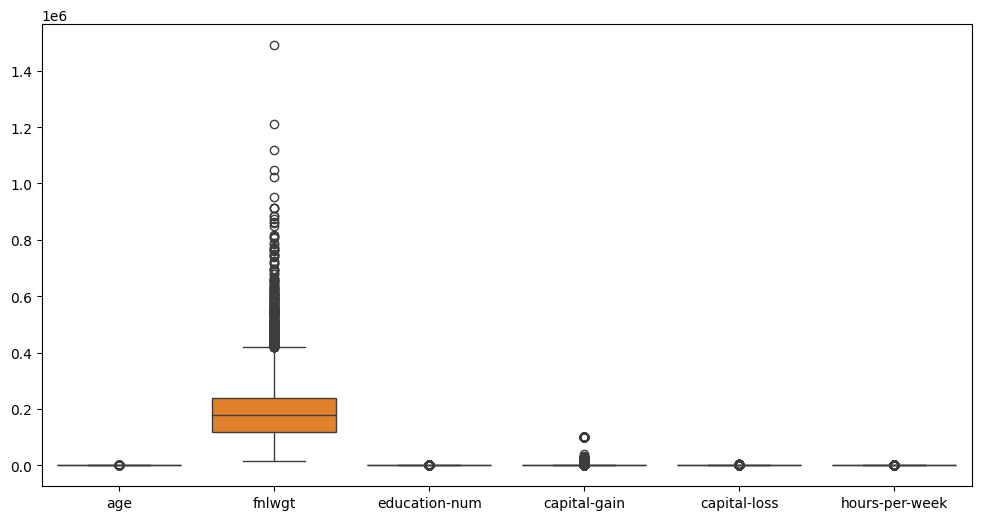

In [19]:
outliers = df.select_dtypes(include="number")  
plt.figure(figsize=(12, 6))
sns.boxplot(data=outliers)
plt.show()

# Removing Features because they have no relation with any other features and the target

In [21]:
df.drop(columns=["fnlwgt", "education-num"], axis = 1, inplace = True)

In [22]:
df.head()

,age,workclass,education,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,11th,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,Some-college,Never-married,Prof-specialty,Own-child,White,Female,0,0,30,United-States,<=50K


In [23]:
categorical_columns = df.select_dtypes(include='object').columns.tolist()  

In [25]:
categorical_columns

['workclass',
 'education',
 'marital-status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native-country',
 'income']

# Visualizing categorical cols

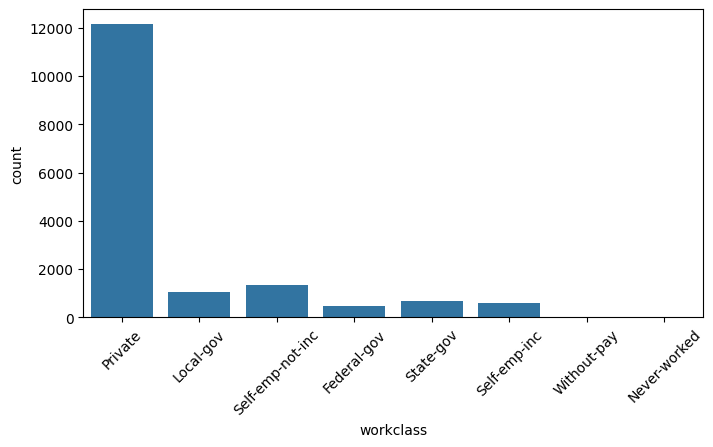

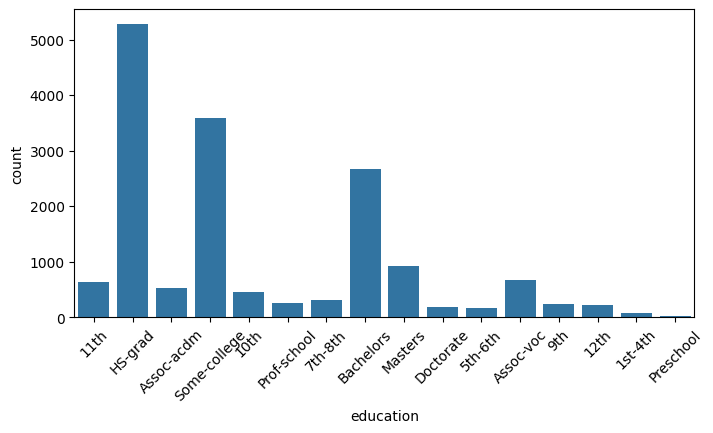

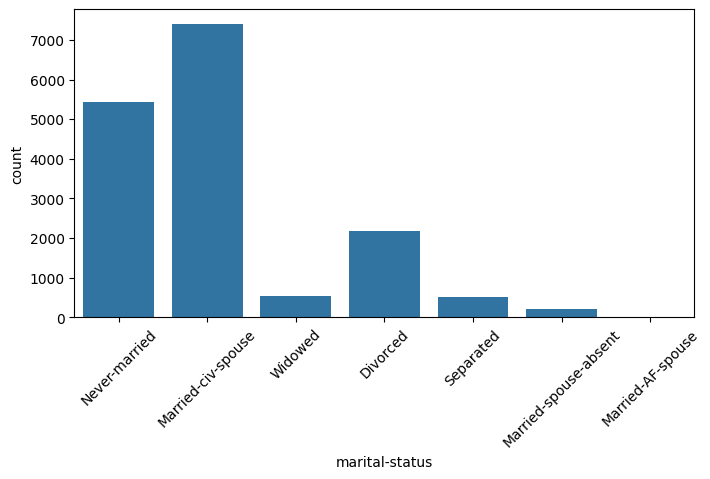

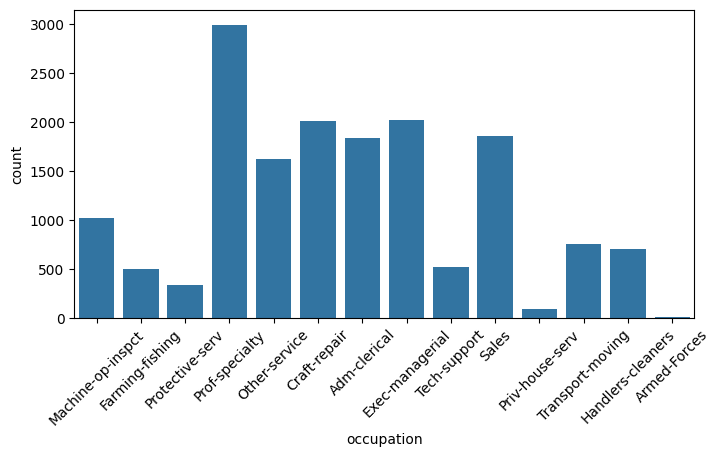

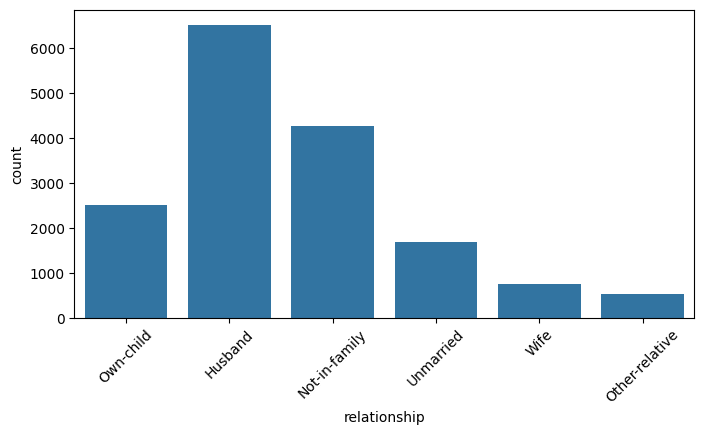

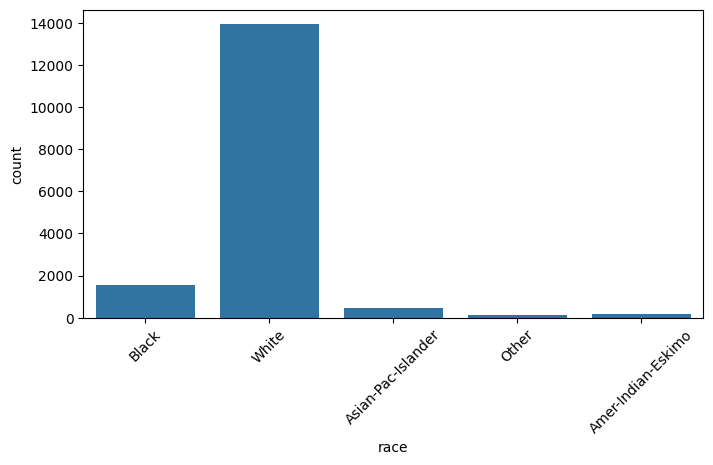

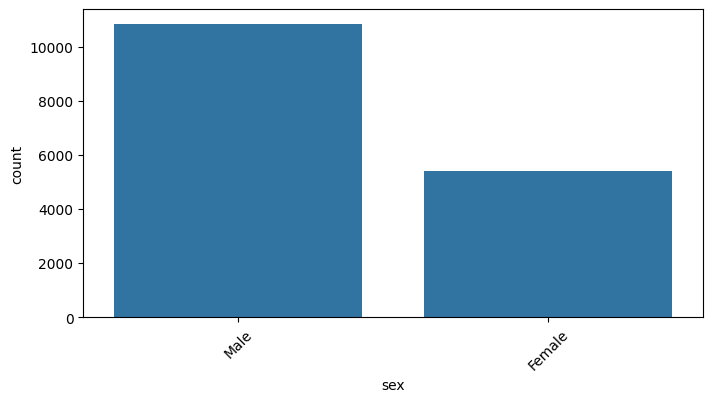

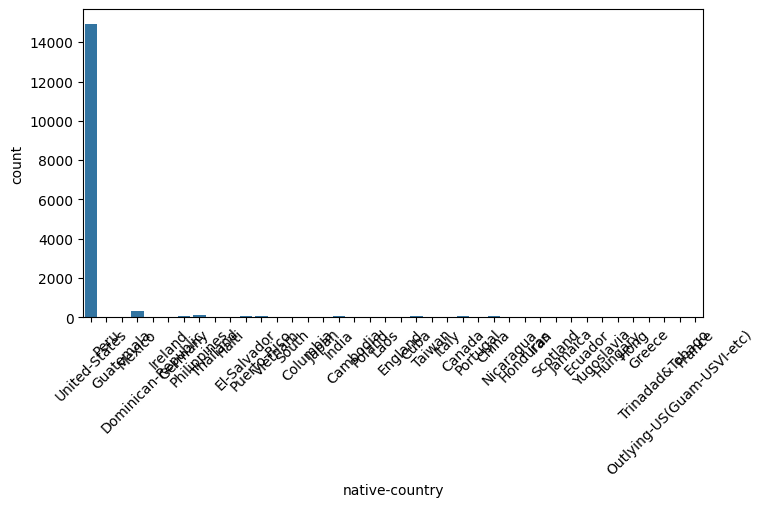

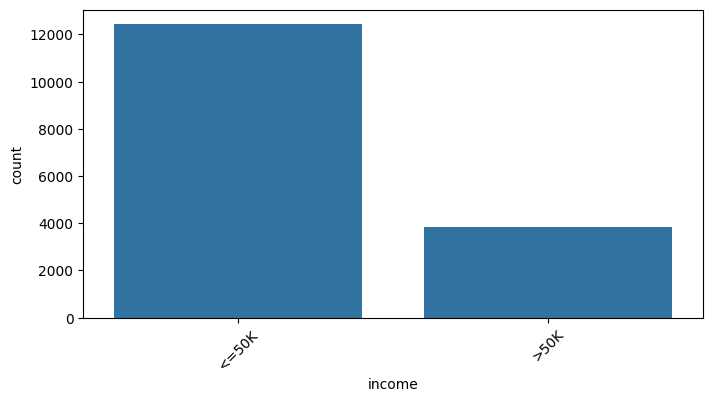

<Figure size 640x480 with 0 Axes>

In [29]:
for i in categorical_columns:
  plt.figure(figsize=(8, 4))
  sns.countplot(data=df, x=i)
  plt.xticks(rotation=45) 
  plt.show()


# visualiziing numerical col

In [33]:
numerical_col = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

In [34]:
numerical_col

['age', 'capital-gain', 'capital-loss', 'hours-per-week']

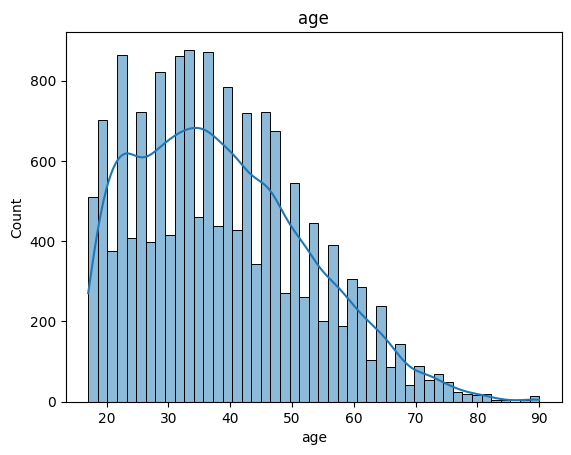

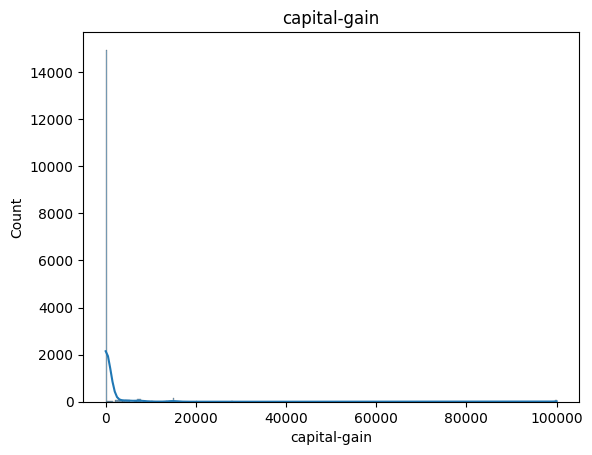

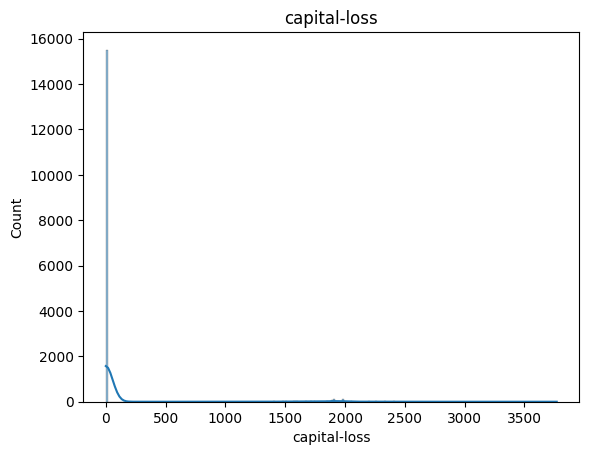

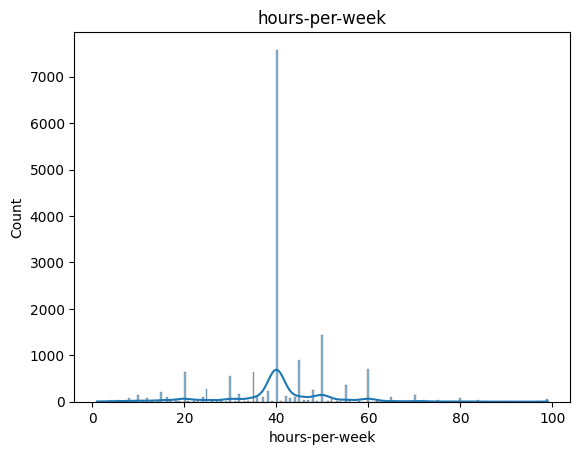

In [36]:
for i in numerical_col:
    sns.histplot(data = df, x = i, kde=True, line_kws={"color": "red"})
    plt.title(label=i)
    plt.show()

# the data is skewed so i will apply log1p function 

# log1p reduces the influence of extremely large values

In [38]:
df["capital-gain"] = np.log1p(df["capital-gain"])
df["capital-loss"] = np.log1p(df["capital-loss"])

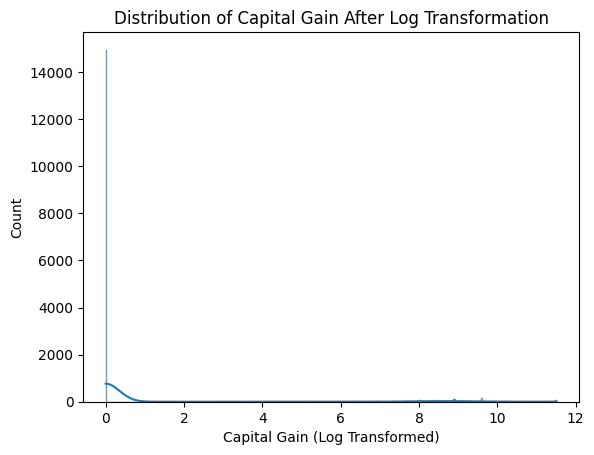

In [40]:
sns.histplot(data=df, x="capital-gain", kde=True, line_kws={"color": "red"})
plt.title(label="Distribution of Capital Gain After Log Transformation")
plt.xlabel("Capital Gain (Log Transformed)")
plt.ylabel("Count")
plt.show()

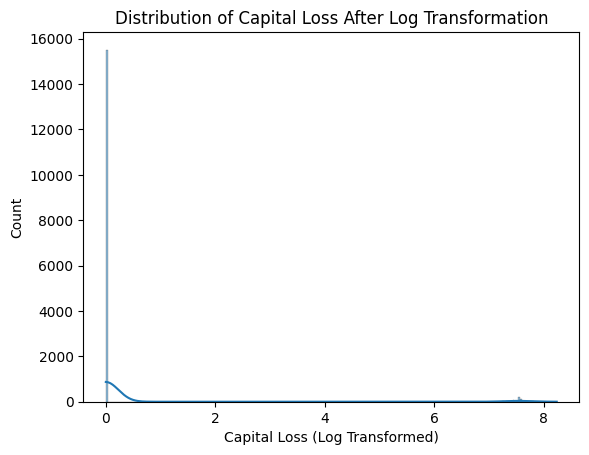

In [42]:
sns.histplot(data=df, x="capital-loss", kde=True, line_kws={"color": "red"})
plt.title(label="Distribution of Capital Loss After Log Transformation")
plt.xlabel("Capital Loss (Log Transformed)")
plt.ylabel("Count")
plt.show()

# CORRELATION 

In [30]:
data_correlation = df.corr(numeric_only=True)

In [31]:
data_correlation

,age,capital-gain,capital-loss,hours-per-week
age,1.000000,0.076352,0.055256,0.076827
capital-gain,0.076352,1.000000,-0.031119,0.089381
capital-loss,0.055256,-0.031119,1.000000,0.054861
hours-per-week,0.076827,0.089381,0.054861,1.000000


In [43]:
df.to_csv("adult_test_cleaned.csv", index=False)